# 24. Analisis keadilan (fairness) terhadap kecerahan citra sebagai proksi pigmentasi
**Penelitian:** Deteksi anemia dari citra pucat (telapak tangan, kuku, konjungtiva) dengan data pooling multi-situs.

**Tujuan:** mengevaluasi apakah model pooled berperforma berbeda antar-kelompok kecerahan citra. Pengelompokan dihitung dari citra (L* rata-rata piksel dengan L>50), bukan pigmentasi kulit tervalidasi, dan dilaporkan dengan tiga cara: ambang L 8-bit lama (100 dan 150), kategori ITA (Chardon, digabung menjadi tiga), dan tertil L* dalam situs (untuk memisahkan efek situs). Metrik per kelompok: sensitivitas, spesifisitas, akurasi, AUC (kosong bila satu kelas) dengan interval Wilson; komposisi situs dan prevalensi per kelompok; kontras bertanda kelompok gelap vs terang (selang Newcombe untuk sensitivitas dan spesifisitas, bootstrap untuk AUC) dan uji permutasi dalam situs untuk selisih maksimum-minimum antar-kelompok (selisih ini selalu nonnegatif sehingga selang bootstrapnya tidak dipakai sebagai bukti disparitas); evaluasi utama memakai prediksi out-of-fold dari validasi silang 5x5 agar kelompok kecil (mis. Dark) memiliki cukup data, dan split tunggal sebagai pelengkap.

**Masukan:** Dataset (Mendeley Data): Palm doi:10.17632/ccr8cm22vz.1, Nail doi:10.17632/2xx4j3kjg2.1, Conjunctiva doi:10.17632/nt7r8hv2pz.1. Letakkan dalam folder `Dataset_Multisite/{Palm,Nail,Conjunctiva}`.

**Keluaran (folder `hasil_revisi`):** `fairness_komposisi_kelompok.csv`, `fairness_cv_oof_per_kelompok.csv`, `fairness_cv_oof_selisih.csv`, `fairness_kontras_berpasangan.csv`, `fairness_split_tunggal.csv`.

**Kaitan dengan naskah:** Tabel 6 (menggantikan Eksperimen 11) dan butir Keterbatasan tentang pengelompokan pigmentasi.

**Cara menjalankan:** Colab, Runtime > Run all. CPU sudah cukup; GPU tidak diperlukan. Seed acak = 42 dan urutan file diurutkan (`sorted`) sehingga hasil dapat direproduksi pada versi pustaka yang dicetak di sel kedua.

In [3]:
!pip install lightgbm -q

In [4]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

Mounted at /content/drive


In [5]:
# ===== FUNGSI BERSAMA (identik di keempat notebook) =====
import os, re, hashlib, warnings
import numpy as np, pandas as pd, cv2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score
from lightgbm import LGBMClassifier
warnings.filterwarnings('ignore')

# ---------- KONFIGURASI (ubah hanya bagian ini) ----------
SEED = 42
BASE = '/content/drive/MyDrive/Dataset_Multisite'   # folder berisi subfolder Palm/, Nail/, Conjunctiva/
OUT  = '/content/drive/MyDrive/hasil_revisi'          # folder keluaran (CSV)
SITES = {'Palm': 0, 'Nail': 1, 'Conjunctiva': 2}
# Filter piksel memeriksa kanal L, R, dan G. Kanal B ikut difilter jika True
# (Appiahene et al. 2023 menuliskan kondisi min < R=G=B < max).
FILTER_INCLUDE_B = False
# True: buang juga citra bernama varian dari citra lain (akhiran FV/RA atau spasi+angka) yang citra dasarnya ada.
BUANG_VARIAN = True
os.makedirs(OUT, exist_ok=True)

# ---------- DAFTAR FILE ----------
def parse_label(name):
    """Label dari awalan nama file (Anemic / Non-Anemic); nama yang mengandung tanda kurung (salinan bernomor) dan awalan tidak dikenali dilewati."""
    if '(' in name: return None
    c = name.lower().replace(' ', '')
    if c.startswith('non-anemic'): return 0
    if c.startswith('anemic'): return 1
    return None

def list_used_files():
    rows = []
    for site, sid in SITES.items():
        d = os.path.join(BASE, site)
        for n in sorted(os.listdir(d)):          # sorted -> urutan deterministik
            lab = parse_label(n)
            if lab is not None:
                rows.append(dict(site=site, site_id=sid, file=n, path=os.path.join(d, n), label=lab))
    return pd.DataFrame(rows)

def md5(path):
    with open(path, 'rb') as f: return hashlib.md5(f.read()).hexdigest()

# ---------- EKSTRAKSI FITUR ----------
def feat_original(img, lo=50, hi=200):
    """Fitur [mean a*, mean b*, mean G] dengan filter piksel. Return (fitur, mask_kosong)."""
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    L, a, b = cv2.split(lab); R, G, B = cv2.split(rgb)
    m = (L > lo) & (L < hi) & (R > lo) & (R < hi) & (G > lo) & (G < hi)
    if FILTER_INCLUDE_B: m &= (B > lo) & (B < hi)
    if m.any(): return [a[m].mean(), b[m].mean(), G[m].mean()], False
    return [0.0, 0.0, 0.0], True

def feat_otsu(img):
    """Fitur dari piksel foreground Otsu (grayscale). Tanpa filter L/R/G. Return (fitur, mask_kosong)."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    _, mk = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = mk > 0
    if not m.any(): return [0.0, 0.0, 0.0], True
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    _, a, b = cv2.split(lab); G = rgb[:, :, 1]
    return [a[m].mean(), b[m].mean(), G[m].mean()], False

# ---------- PEMBAGIAN DATA & EVALUASI ----------
def split_idx(y, scheme, seed=SEED):
    """Return (train, val, test) berupa indeks. Skema: '80:20', '80:10:10', '70:10:20'."""
    idx = np.arange(len(y))
    if scheme == '80:20':
        tr, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        return tr, None, te
    if scheme == '80:10:10':
        tr, tmp = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        va, te = train_test_split(tmp, test_size=0.50, stratify=y[tmp], random_state=seed)
        return tr, va, te
    if scheme == '70:10:20':
        trva, te = train_test_split(idx, test_size=0.20, stratify=y, random_state=seed)
        tr, va = train_test_split(trva, test_size=0.125, stratify=y[trva], random_state=seed)
        return tr, va, te
    raise ValueError(scheme)

def metrics_from(yte, pred, proba):
    tn, fp, fn, tp = confusion_matrix(yte, pred, labels=[0, 1]).ravel()
    assert tn + fp + fn + tp == len(yte), 'TP+TN+FP+FN harus sama dengan jumlah data uji'
    two = len(set(yte)) == 2
    return dict(n_test=len(yte), n_test_anemic=int((yte == 1).sum()), TP=int(tp), TN=int(tn), FP=int(fp), FN=int(fn),
                acc=100*(tp+tn)/len(yte),
                sens=100*tp/(tp+fn) if tp+fn else np.nan,
                spec=100*tn/(tn+fp) if tn+fp else np.nan,
                f1=100*f1_score(yte, pred, zero_division=0),
                auc=100*roc_auc_score(yte, proba) if two else np.nan,
                baseline_mayoritas=100*max((yte == 1).mean(), (yte == 0).mean()))

def fit_lgbm(Xtr, ytr):
    sc = StandardScaler().fit(Xtr)
    m = LGBMClassifier(n_estimators=100, random_state=SEED, verbose=-1).fit(sc.transform(Xtr), ytr)
    return sc, m

def predict_lgbm(sc, m, X):
    proba = m.predict_proba(sc.transform(X))[:, 1]
    return (proba >= 0.5).astype(int), proba

def tandai_dibuang(df):
    """Array boolean (urut baris): True bila baris dibuang pada pembersihan = salinan identik MD5 (satu dipertahankan),
    kedua file pada pasangan identik berlabel berbeda, dan (bila BUANG_VARIAN) citra varian FV/RA. df: indeks 0..n-1 dan kolom md5."""
    konflik = df.groupby('md5').label.transform('nunique') > 1
    dibuang = np.array(df.duplicated('md5', keep='first') | konflik, dtype=bool)   # salinan yang dapat diubah
    if BUANG_VARIAN:
        posisi = np.flatnonzero(~dibuang)
        for a, b in pasangan_varian(df.iloc[posisi].reset_index(drop=True)): dibuang[posisi[a]] = True
    return dibuang

def bersihkan(df):
    """Data bersih untuk semua eksperimen (satu definisi tunggal)."""
    df = df.reset_index(drop=True).copy(); df['md5'] = df['path'].map(md5)
    return df[~tandai_dibuang(df)].reset_index(drop=True)

def cek_kebocoran(md5s, tr, va, te, wajib=True):
    """Pemeriksaan kebocoran: indeks latih/validasi/uji harus saling lepas dan tidak ada citra identik (MD5) lintas partisi.
    Return jumlah citra identik lintas partisi, mis. {'latih-uji': 0}. wajib=True -> hentikan program bila ada pelanggaran."""
    parts = {'latih': set(tr), 'uji': set(te)}
    if va is not None: parts['val'] = set(va)
    nm = sorted(parts)
    for i, a in enumerate(nm):
        for b in nm[i + 1:]:
            assert not (parts[a] & parts[b]), f'Indeks tumpang tindih: {a}-{b}'
    m = {k: set(np.asarray(md5s)[sorted(v)]) for k, v in parts.items()}
    bocor = {f'{a}-{b}': len(m[a] & m[b]) for i, a in enumerate(nm) for b in nm[i + 1:]}
    if wajib: assert all(v == 0 for v in bocor.values()), f'Citra identik lintas partisi: {bocor}'
    return bocor

def pasangan_varian(df):
    """Pasangan (indeks varian, indeks citra dasar) pada df (indeks posisi 0..n-1): nama berakhiran FV/RA atau spasi+angka
    yang nama dasarnya ada pada situs yang sama (mis. Anemic-001FV dengan Anemic-001)."""
    stem = df.file.str.replace(r'\.[A-Za-z]+$', '', regex=True)
    base = stem.str.replace(r'\s\d+$', '', regex=True).str.replace(r'(FV|RA)$', '', regex=True)
    key = {(s, t): i for i, (s, t) in enumerate(zip(df.site, stem))}
    return [(i, key[(s, b)]) for i, (s, t, b) in enumerate(zip(df.site, stem, base)) if b != t and (s, b) in key]

def cek_varian(pasangan, tr, va, te):
    """Jumlah pasangan varian-dasar yang terpisah di partisi berbeda (informasi; idealnya 0)."""
    part = {}
    for ids, nm in [(tr, 'latih'), (va, 'val'), (te, 'uji')]:
        if ids is not None:
            for i in ids: part[i] = nm
    return sum(1 for a, b in pasangan if a in part and b in part and part[a] != part[b])

In [6]:
import sys, numpy, pandas, cv2, sklearn, lightgbm
print('Python', sys.version.split()[0], '| numpy', numpy.__version__, '| pandas', pandas.__version__,
      '| OpenCV', cv2.__version__, '| scikit-learn', sklearn.__version__, '| LightGBM', lightgbm.__version__, '| SEED', SEED)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | OpenCV 4.14.0 | scikit-learn 1.6.1 | LightGBM 4.6.0 | SEED 42


In [7]:
# ===== ANALISIS KEADILAN (FAIRNESS) TERHADAP KECERAHAN/PIGMENTASI CITRA (menggantikan Eksperimen 11) =====
# Data bersih; pengelompokan dari citra (proksi, bukan pigmentasi kulit tervalidasi); metrik per kelompok (sensitivitas, spesifisitas,
# interval Wilson); evaluasi out-of-fold dari validasi silang berulang agar kelompok kecil memiliki cukup data; selisih antar-kelompok
# dengan selang kepercayaan bootstrap; split tunggal sebagai pelengkap.
from sklearn.model_selection import RepeatedStratifiedKFold

N_SPLITS, N_REPEATS, N_BOOT = 5, 5, 1000
MIN_PER_KELAS = 10                    # kelompok dipakai untuk selisih bila tiap kelas >= nilai ini
FITUR_OPSI = ['Original', 'Otsu']     # Original = filter L,R,G (seperti laporan); Otsu = seleksi piksel Otsu tanpa filter

df = bersihkan(list_used_files())
assert df.md5.is_unique and not pasangan_varian(df), 'Data belum bersih'
y = df.label.to_numpy(); site = df.site_id.to_numpy(float); n = len(y)
imgs_stat, FT = [], {'Original': [], 'Otsu': []}
for p in df.path:
    img = cv2.imread(p)
    FT['Original'].append(feat_original(img)[0]); FT['Otsu'].append(feat_otsu(img)[0])
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); L8, b8 = lab[..., 0].astype(np.float32), lab[..., 2].astype(np.float32)
    m = L8 > 50
    if not m.any(): m = np.ones_like(m, bool)
    Ls = L8[m].mean() * 100 / 255; bs = b8[m].mean() - 128           # L* (0-100) dan b* dari L 8-bit OpenCV
    imgs_stat.append((L8[m].mean(), Ls, np.degrees(np.arctan2(Ls - 50, bs))))
FT = {k: np.array(v) for k, v in FT.items()}
st = np.array(imgs_stat); df['L8'], df['Lstar'], df['ITA'] = st[:, 0], st[:, 1], st[:, 2]

# ---------- tiga cara pengelompokan ----------
def grp_L8(v): return 'Gelap (L<100)' if v < 100 else ('Sedang (100<=L<150)' if v < 150 else 'Terang (L>=150)')        # ambang kode lama, skala 8-bit
def grp_ita(v): return 'Terang (ITA>=41)' if v >= 41 else ('Menengah (10<=ITA<41)' if v >= 10 else 'Gelap (ITA<10)')  # penggabungan kategori Chardon
df['G_L8'] = df.L8.map(grp_L8)
df['G_ITA'] = df.ITA.map(grp_ita)
df['G_tertil_situs'] = df.groupby('site').Lstar.transform(lambda s: pd.qcut(s, 3, labels=['T1 gelap', 'T2 tengah', 'T3 terang']).astype(str))
GROUPINGS = {'L 8-bit (ambang kode lama)': 'G_L8', 'ITA (Chardon, digabung)': 'G_ITA', 'Tertil L* dalam situs': 'G_tertil_situs'}

komp = []
for gn, col in GROUPINGS.items():
    for g, d in df.groupby(col):
        komp.append(dict(pengelompokan=gn, kelompok=g, n=len(d), anemic=int(d.label.sum()), prevalensi_anemic=round(100 * d.label.mean(), 1),
                         **{f'n_{s}': int((d.site == s).sum()) for s in SITES}))
komp = pd.DataFrame(komp); komp.to_csv(os.path.join(OUT, 'fairness_komposisi_kelompok.csv'), index=False)
print('Komposisi kelompok (situs dan prevalensi):'); print(komp.to_string(index=False))

# ---------- metrik per kelompok ----------
def wilson(k, nn, z=1.96):
    if nn == 0: return (np.nan, np.nan)
    p = k / nn; d = 1 + z * z / nn; c = (p + z * z / (2 * nn)) / d; h = z * np.sqrt(p * (1 - p) / nn + z * z / (4 * nn * nn)) / d
    return 100 * (c - h), 100 * (c + h)
def grup_metrik(yt, pr, pb):
    tp = int(((pr == 1) & (yt == 1)).sum()); tn = int(((pr == 0) & (yt == 0)).sum()); fp = int(((pr == 1) & (yt == 0)).sum()); fn = int(((pr == 0) & (yt == 1)).sum())
    npos, nneg = tp + fn, tn + fp
    r = dict(n=len(yt), n_anemic=npos, n_non=nneg, TP=tp, TN=tn, FP=fp, FN=fn, acc=100 * (tp + tn) / max(len(yt), 1),
             sens=100 * tp / npos if npos else np.nan, spec=100 * tn / nneg if nneg else np.nan,
             auc=100 * roc_auc_score(yt, pb) if (npos and nneg) else np.nan, n_cukup=bool(npos >= MIN_PER_KELAS and nneg >= MIN_PER_KELAS))
    r['sens_ci_bawah'], r['sens_ci_atas'] = wilson(tp, npos); r['spec_ci_bawah'], r['spec_ci_atas'] = wilson(tn, nneg)
    return r

def tabel_kelompok(yt, pr, pb, gser, label):
    rows = [dict(kelompok='Keseluruhan', **grup_metrik(yt, pr, pb))]
    for g in sorted(pd.unique(gser)):
        k = np.asarray(gser) == g; rows.append(dict(kelompok=g, **grup_metrik(yt[k], pr[k], pb[k])))
    return pd.DataFrame(rows).assign(**label)

# ---------- (1) OUT-OF-FOLD dari validasi silang berulang ----------
strat = (site * 2 + y).astype(int)
folds = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=SEED).split(np.zeros(n), strat))
OOF = {}
for fk in FITUR_OPSI:
    X = np.column_stack([FT[fk], site]); P = np.zeros((n, N_REPEATS))
    for i, (tr, te) in enumerate(folds):
        sc, m = fit_lgbm(X[tr], y[tr]); _, pb = predict_lgbm(sc, m, X[te]); P[te, i // N_SPLITS] = pb
    OOF[fk] = P
    print(f'\n[{fk}] AUC keseluruhan per pengulangan: ' + ', '.join(f'{100*roc_auc_score(y, P[:, r]):.2f}' for r in range(N_REPEATS)))
tabs, gaps, kontras = [], [], []
rng = np.random.default_rng(SEED)
PASANG = {'L 8-bit (ambang kode lama)': ('Gelap (L<100)', 'Terang (L>=150)'), 'ITA (Chardon, digabung)': ('Gelap (ITA<10)', 'Terang (ITA>=41)'),
          'Tertil L* dalam situs': ('T1 gelap', 'T3 terang')}
def newcombe(k1, n1, k2, n2):             # selang kepercayaan Newcombe-Wilson untuk selisih dua proporsi (persen)
    def w(k, nn, z=1.96):
        p = k / nn; d = 1 + z * z / nn; c = (p + z * z / (2 * nn)) / d; h = z * np.sqrt(p * (1 - p) / nn + z * z / (4 * nn * nn)) / d; return p, c - h, c + h
    p1, l1, u1 = w(k1, n1); p2, l2, u2 = w(k2, n2); d = p1 - p2
    return 100 * d, 100 * (d - np.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)), 100 * (d + np.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))
for fk in FITUR_OPSI:
    Pm = OOF[fk].mean(axis=1); pr = (Pm >= 0.5).astype(int)
    for gn, col in GROUPINGS.items():
        g = df[col].to_numpy(); t = tabel_kelompok(y, pr, Pm, g, dict(fitur=fk, pengelompokan=gn)); tabs.append(t)
        # kontras berpasangan bertanda: kelompok paling gelap vs paling terang
        a, c = PASANG[gn]
        if (t.kelompok == a).any() and (t.kelompok == c).any():
            a, c = PASANG[gn]; A = t[t.kelompok == a].iloc[0]; C = t[t.kelompok == c].iloc[0]
            ds, lo_s, hi_s = newcombe(A.TP, A.n_anemic, C.TP, C.n_anemic); dp, lo_p, hi_p = newcombe(A.TN, A.n_non, C.TN, C.n_non)
            ia, ic = np.where(g == a)[0], np.where(g == c)[0]; db = []
            for _ in range(N_BOOT):
                ra, rc = rng.choice(ia, len(ia)), rng.choice(ic, len(ic))
                if len(set(y[ra])) == 2 and len(set(y[rc])) == 2: db.append(100 * (roc_auc_score(y[ra], Pm[ra]) - roc_auc_score(y[rc], Pm[rc])))
            kontras.append(dict(fitur=fk, pengelompokan=gn, kelompok_gelap=a, kelompok_terang=c, selisih_sens=ds, ci_bawah_sens=lo_s, ci_atas_sens=hi_s,
                                selisih_spes=dp, ci_bawah_spes=lo_p, ci_atas_spes=hi_p, selisih_auc=A.auc - C.auc,
                                ci_bawah_auc=np.percentile(db, 2.5) if db else np.nan, ci_atas_auc=np.percentile(db, 97.5) if db else np.nan))
        # selisih maks-min antar-kelompok dan uji permutasi (label kelompok diacak DI DALAM situs agar komposisi situs tetap)
        ok = [k for k in sorted(pd.unique(g)) if t[(t.kelompok == k)].n_cukup.iloc[0]]
        if len(ok) >= 2:
            def gap(gv):
                s, sp = [], []
                for k in ok:
                    kk = gv == k; s.append((pr[kk & (y == 1)] == 1).mean() * 100); sp.append((pr[kk & (y == 0)] == 0).mean() * 100)
                return max(s) - min(s), max(sp) - min(sp)
            obs = gap(g); nul = []
            for _ in range(N_BOOT):
                gp = g.copy()
                for sv in np.unique(site): ix = np.where(site == sv)[0]; gp[ix] = rng.permutation(g[ix])
                nul.append(gap(gp))
            nul = np.array(nul)
            gaps.append(dict(fitur=fk, pengelompokan=gn, kelompok_dipakai=' | '.join(ok), selisih_maks_min_sens=obs[0], p_permutasi_sens=(1 + (nul[:, 0] >= obs[0]).sum()) / (N_BOOT + 1),
                             selisih_maks_min_spes=obs[1], p_permutasi_spes=(1 + (nul[:, 1] >= obs[1]).sum()) / (N_BOOT + 1)))
        else:
            gaps.append(dict(fitur=fk, pengelompokan=gn, kelompok_dipakai='kurang dari 2 kelompok memenuhi n minimum'))
oof_df = pd.concat(tabs, ignore_index=True).round(2); oof_df.to_csv(os.path.join(OUT, 'fairness_cv_oof_per_kelompok.csv'), index=False)
gap_df = pd.DataFrame(gaps).round(3); gap_df.to_csv(os.path.join(OUT, 'fairness_cv_oof_selisih.csv'), index=False)
kon_df = pd.DataFrame(kontras).round(2); kon_df.to_csv(os.path.join(OUT, 'fairness_kontras_berpasangan.csv'), index=False)
print('\n=== Out-of-fold (rata-rata probabilitas lintas pengulangan), per kelompok ===')
print(oof_df[['fitur', 'pengelompokan', 'kelompok', 'n', 'n_anemic', 'n_non', 'acc', 'sens', 'sens_ci_bawah', 'sens_ci_atas', 'spec', 'spec_ci_bawah', 'spec_ci_atas', 'auc', 'n_cukup']].to_string(index=False))
print('\n=== Kontras bertanda gelap - terang (selang Newcombe untuk sens/spes, bootstrap untuk AUC) ==='); print(kon_df.to_string(index=False))
print('\n=== Selisih maks-min antar-kelompok + uji permutasi dalam situs (maks-min selalu >= 0; gunakan p, bukan selisihnya) ==='); print(gap_df.to_string(index=False))

# ---------- (2) split tunggal (pelengkap) ----------
rows = []
for scheme in ['70:10:20', '80:10:10']:
    tr, va, te = split_idx(y, scheme); print(f'\nSkema {scheme}: kebocoran', cek_kebocoran(df.md5.to_numpy(), tr, va, te), '| uji =', len(te))
    for fk in FITUR_OPSI:
        X = np.column_stack([FT[fk], site]); sc, m = fit_lgbm(X[tr], y[tr]); pr, pb = predict_lgbm(sc, m, X[te])
        for gn, col in GROUPINGS.items():
            rows.append(tabel_kelompok(y[te], pr, pb, df[col].to_numpy()[te], dict(skema=scheme, fitur=fk, pengelompokan=gn)))
sp = pd.concat(rows, ignore_index=True).round(2); sp.to_csv(os.path.join(OUT, 'fairness_split_tunggal.csv'), index=False)
print(sp[sp.fitur == 'Original'][['skema', 'pengelompokan', 'kelompok', 'n', 'n_anemic', 'n_non', 'acc', 'sens', 'spec', 'auc', 'n_cukup']].to_string(index=False))

Komposisi kelompok (situs dan prevalensi):
             pengelompokan              kelompok   n  anemic  prevalensi_anemic  n_Palm  n_Nail  n_Conjunctiva
L 8-bit (ambang kode lama)         Gelap (L<100)  86      51               59.3      21       6             59
L 8-bit (ambang kode lama)   Sedang (100<=L<150) 485     315               64.9     216      73            196
L 8-bit (ambang kode lama)       Terang (L>=150) 774     519               67.1     282     233            259
   ITA (Chardon, digabung)        Gelap (ITA<10) 368     225               61.1     157      36            175
   ITA (Chardon, digabung) Menengah (10<=ITA<41) 427     267               62.5     184      60            183
   ITA (Chardon, digabung)      Terang (ITA>=41) 550     393               71.5     178     216            156
     Tertil L* dalam situs              T1 gelap 450     303               67.3     174     104            172
     Tertil L* dalam situs             T2 tengah 447     299         

In [8]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT = '/content/drive/MyDrive/hasil_revisi'          # folder berisi CSV hasil
LABEL = ['Non-anemic', 'Anemic']

def cm_dari_baris(r):
    """Matriks [[TN, FP], [FN, TP]]: baris = kelas sebenarnya, kolom = prediksi."""
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]], dtype=int)
    n = r['n_test'] if 'n_test' in r.index else r['n']
    assert cm.sum() == n, f'TP+TN+FP+FN ({cm.sum()}) harus sama dengan jumlah data ({n})'
    return cm

def gambar_cm(cm, judul, ax):
    pct = cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None) * 100      # persen per kelas sebenarnya
    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i, j]}\n({pct[i, j]:.1f}%)', ha='center', va='center', fontsize=9,
                    color='white' if pct[i, j] > 50 else 'black')
    ax.set_xticks([0, 1]); ax.set_xticklabels(LABEL, fontsize=8); ax.set_yticks([0, 1]); ax.set_yticklabels(LABEL, fontsize=8)
    ax.set_xlabel('Prediksi'); ax.set_ylabel('Sebenarnya'); ax.set_title(judul, fontsize=8)

def grid_cm(df, judul, ncol=4, simpan=None, judul_utama=''):
    n = len(df); nrow = int(np.ceil(n / ncol))
    fig, axs = plt.subplots(nrow, ncol, figsize=(3.3 * ncol, 3.4 * nrow), squeeze=False)
    for ax in axs.ravel(): ax.axis('off')
    for ax, (_, r) in zip(axs.ravel(), df.iterrows()):
        ax.axis('on'); gambar_cm(cm_dari_baris(r), judul(r), ax)
    fig.suptitle(judul_utama); plt.tight_layout()
    if simpan: plt.savefig(os.path.join(OUT, simpan), dpi=150)
    plt.show()

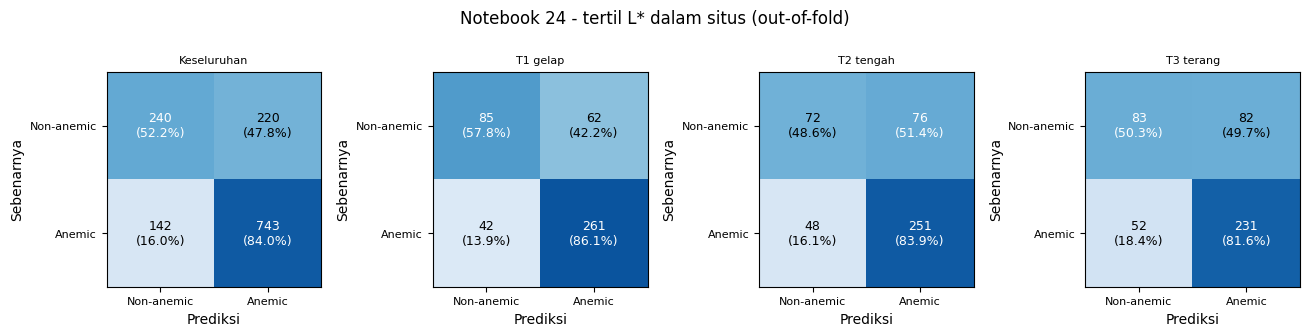

In [9]:
f = pd.read_csv(f'{OUT}/fairness_cv_oof_per_kelompok.csv')
d = f[(f.fitur == 'Original') & (f.pengelompokan == 'Tertil L* dalam situs')]  # atau 'ITA (Chardon, digabung)' / 'L 8-bit (ambang kode lama)'
grid_cm(d, lambda r: r['kelompok'], ncol=4, simpan='cm_nb24.png', judul_utama='Notebook 24 - tertil L* dalam situs (out-of-fold)')